# 01. Completeness of the atmosphere initial states

## Purpose

Show what each test's atmosphere initial file holds compared with the production files. Checks: are the radiative gases, aerosols, hydrometeor numbers and sea-ice/surface fields present and non-zero? How large are their global means and zonal profiles (total ozone, radiative water vapour, aerosol burdens, cloud-droplet number, 50-hPa temperature)? Do the completed ERA5 files keep the ERA5 fields unchanged?

Issues found in the ERA5-initialized F20TR hindcasts (HYB_BASE, DA_LND) and tested here, all from the start of 16 Dec 2011:

1. **Incomplete ERA5 atmosphere.** `DART_INIT/ATM/v3.LR.ne30pg2.ERA5.eam.i.<date>.nc` holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero. That includes the radiation's gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), the aerosols and the hydrometeor numbers. HYB_BASE and DA_LND therefore start radiatively dry and without ozone, about 6 K too cold over land.
2. **Which fields fill the gap.** The completed states take ERA5's T, U, V, Q, PS, CLDLIQ and CLDICE and everything else from either the DART ensemble mean (`ERA5_DARTFILL`, the HYB_BASE rebuild) or the free-running CLIM_BASE state (`ERA5_CLIMFILL`). `ensemble_perturbations/util/complete_era5_ic.py` does the completion. H2OLNZ follows the ERA5 Q.
3. **Atmosphere and land benefits with complete states.** The production DA_LND (bare ERA5 atmosphere) and DA_ATM (DATM land) mix the IC defect into the component contrasts. CLIMO_ATM and CLIMO_LND instead replace one component of DA_COUPLED EN40 with the complete CLIM_BASE state (Berner-style).

Every test is a single member, so a difference A − B is judged against `ev.noise_scale`: √2 × the member spread of the 20-member DA_COUPLED ensemble of the same start. Beyond the first days, a difference smaller than this cannot be told apart from the chaotic divergence of two members.

## Inputs and outputs

Inputs: the atmosphere initial file of every run (`ic_util/ic_test_runs.py`, relative to `IC_ROOT`), plus the CLIM_BASE (FREE_CLIM) state.
Outputs: `data/era5_ic_test/initial_states/ic_summary.csv`, `ic_era5_field_check.csv`, `ic_zonal_means.nc`; figure `figure/era5_ic_test/initial_states/ic_zonal_means.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
WORKFLOW_NAME = "era5_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_DARTFILL", "ERA5_CLIMFILL", "DA_COUPLED", "DA_ATM", "DA_LND", "CLIMO_ATM", "CLIMO_LND")
EXTRA_STATES = ("CLIM_BASE state",)
BARE_RUN = "ERA5_BARE"                                   # the bare ERA5 file the completed files are checked against
COMPLETED_RUNS = ("ERA5_DARTFILL", "ERA5_CLIMFILL")
TOPIC = "initial_states"
FORCE_COMPUTE = False
FIGURE_DPI = 200
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
for p in (repo / "era5_ic_test", repo / "diagnostic"):     # ic_util (this directory), util (shared readers)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from ic_util import ic_test_eval as ev
from ic_util.ic_test_runs import COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/initial_states
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/initial_states


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_DARTFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5COMPLETE_...,EN01,test,ERA5 + DART-mean fields,DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01
DA_COUPLED,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_20...,EN40,production,DART EN40,DART EN40
DA_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_201112...,EN40,production,DART EN40,DATM EN40
DA_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_201112...,EN40,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DART EN40
CLIMO_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_ATM_TES...,EN40,test,CLIM_BASE + (DART EN40 - DART mean),DART EN40
CLIMO_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_LND_TES...,EN40,test,DART EN40,CLIM_BASE (FREE_CLIM)


,A,B,question
comparison,,,
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


## 4. Global summary of every initial file

Runs that share a file are listed together (`used by`). "Missing" names fields that are absent or zero everywhere. Burdens and columns are area-weighted global means over the dynamics columns (`area_d`). "T level" is the model level nearest the given pressure.

In [4]:
from ic_util.ic_test_runs import ic_path

files = {}
for k in list(RUN_KEYS) + list(EXTRA_STATES):
    files.setdefault(ic_path(k, IC_ROOT).resolve(), []).append(k)
grid = ev.ic_grid(ic_path("DA_COUPLED", IC_ROOT))
stamp = "|".join(f"{p}:{p.stat().st_mtime_ns}" for p in files)


def build_summary():
    rows, zonal = [], []
    for p, keys in files.items():
        row, z = ev.ic_summary(p, grid)
        rows.append(dict(state=" / ".join(keys), **row))
        zonal.append(z.expand_dims(state=[" / ".join(keys)]))
        print(f"[IC] {' / '.join(keys)}: {p.name}")
    return pd.DataFrame(rows), xr.concat(zonal, "state")


summary_file, zonal_file = data_dir / "ic_summary.csv", data_dir / "ic_zonal_means.nc"
built = {}


def built_summary():
    """Read every file once, for both the table and the zonal means."""
    if "x" not in built:
        built["x"] = build_summary()
    return built["x"]


summary = cached_table(summary_file, lambda: built_summary()[0], stamp, force=FORCE_COMPUTE)


def zonal_build():
    ds = built_summary()[1]
    return ds.assign_coords(state=ds.state.astype(str)).rename({v: v.replace("/", " per ") for v in ds.data_vars})


zonal = cached_dataset(zonal_file, zonal_build, stamp, force=FORCE_COMPUTE)
pd.set_option("display.max_colwidth", 60)
display(summary.set_index("state").T)

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/initial_states/ic_summary.csv
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/initial_states/ic_zonal_means.nc


state,ERA5_BARE,ERA5_DARTFILL,ERA5_CLIMFILL,DA_COUPLED / DA_ATM / CLIMO_LND,DA_LND,CLIMO_ATM,CLIM_BASE state
file,HYB_DARTPERT20.EN01.eam.i.2011-12-16-00000.nc,ERA5COMPLETE_DARTPERT20.EN01.eam.i.2011-12-16-00000.nc,ERA5CLIMFILL_DARTPERT20.EN01.eam.i.2011-12-16-00000.nc,DARTEN40_F20TR_ne30pg2_r05_IcoswISC30E3r5_compy.EN40.eam...,v3.LR.ne30pg2.ERA5.eam.i.2011-12-16-00000.nc,CLIMOATM_DARTPERT20.EN40.eam.i.2011-12-16-00000.nc,F20TR_ne30pg2_r05_IcoswISC30E3r5.FREE_CLIM.eam.i.2011-12...
state fields,7,94,94,94,7,94,94
all-zero fields,0,8,8,8,0,8,8
missing radiative gases,"H2OLNZ, O3, N2OLNZ, CH4LNZ",-,-,-,"H2OLNZ, O3, N2OLNZ, CH4LNZ",-,-
missing aerosols,"num_a1, so4_a1, bc_a1, dst_a1, pom_a1",-,-,-,"num_a1, so4_a1, bc_a1, dst_a1, pom_a1",-,-
missing hydrometeor numbers,"NUMLIQ, NUMICE",-,-,-,"NUMLIQ, NUMICE",-,-
missing sea ice / surface,"ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE"
TOZ (DU),NaN,275.940858,267.732744,275.872967,NaN,267.708026,267.712605
column Q (kg m-2),22.828264,22.828264,22.828264,22.962984,22.828264,25.017069,24.986665
column H2OLNZ (kg m-2),NaN,22.87024,22.667592,22.854412,NaN,24.790498,24.794615


## 5. Are the ERA5 fields unchanged in the completed files?

Maximum absolute difference from the bare ERA5 file. Zero means the completion kept the ERA5 value at every column and level.

In [5]:
def build_check():
    bare = ic_path(BARE_RUN, IC_ROOT)
    return pd.DataFrame([dict(run=k, **ev.era5_field_check(ic_path(k, IC_ROOT), bare, grid)) for k in COMPLETED_RUNS])


check = cached_table(data_dir / "ic_era5_field_check.csv", build_check, stamp, force=FORCE_COMPUTE)
display(check.set_index("run"))

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/initial_states/ic_era5_field_check.csv


,T,U,V,Q,PS,CLDLIQ,CLDICE
run,,,,,,,
ERA5_DARTFILL,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERA5_CLIMFILL,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Zonal means

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/initial_states/ic_zonal_means.png


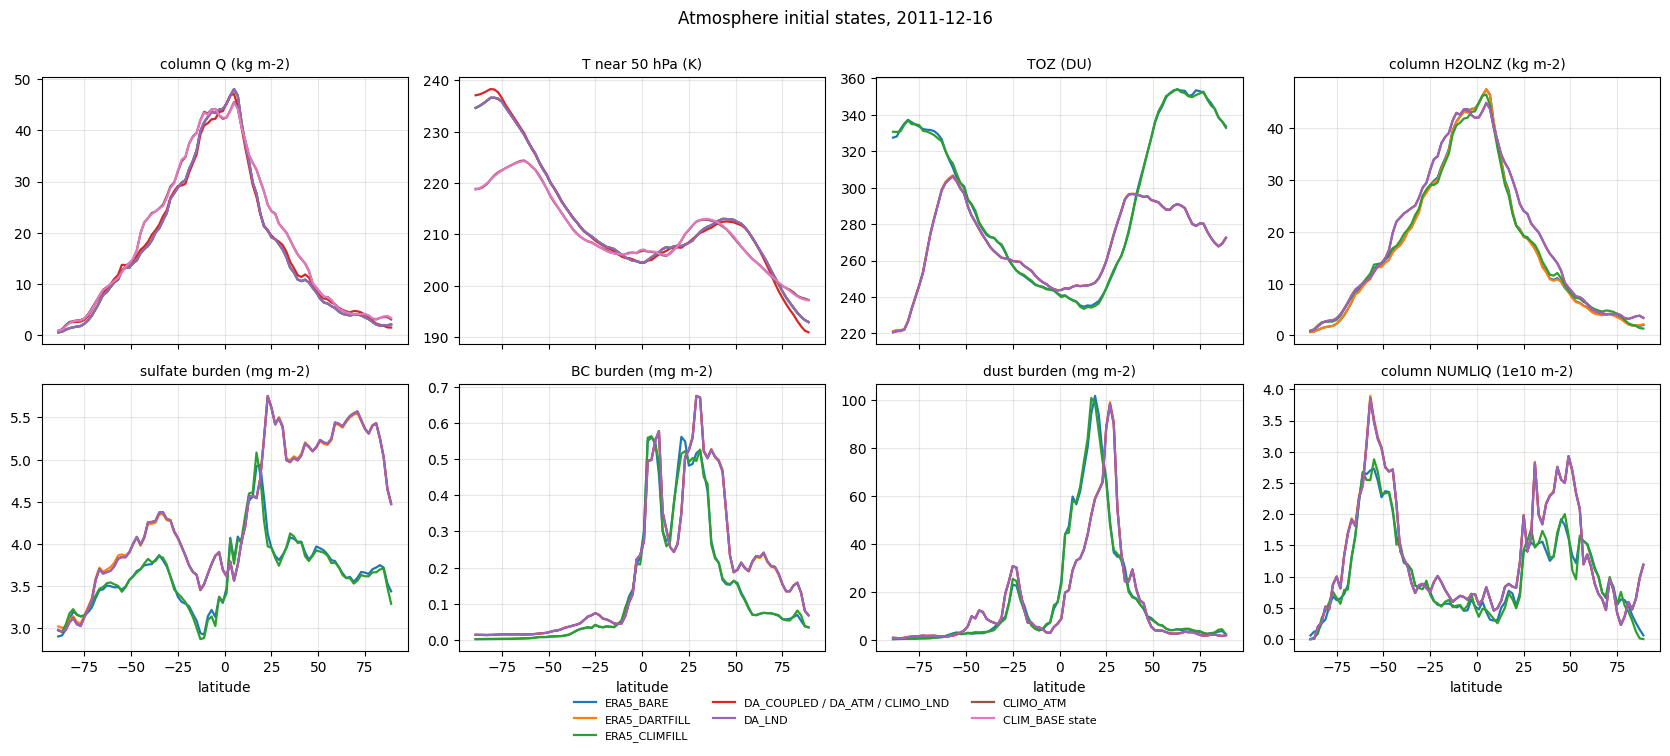

In [6]:
names = list(zonal.data_vars)
fig, axes = plt.subplots(2, (len(names) + 1) // 2, figsize=(4.2 * ((len(names) + 1) // 2), 7.0), sharex=True)
for ax, v in zip(axes.flat, names):
    for s in zonal.state.values:
        y = zonal[v].sel(state=s)
        if y.notnull().any():
            ax.plot(zonal.lat, y, label=s, lw=1.6)
    ax.set_title(v, fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("latitude")
for ax in list(axes.flat)[len(names):]:
    ax.axis("off")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Atmosphere initial states, {INIT}", y=1.0)
fig.tight_layout()
save(fig, "ic_zonal_means.png")
plt.show()